![MuJoCo banner](https://raw.githubusercontent.com/google-deepmind/mujoco/main/banner.png)

# All imports

In [ ]:
!pip install mujoco

# Set up GPU rendering.
from google.colab import files
import distutils.util
import os
import subprocess
try:
  subprocess.run('nvidia-smi')
  use_GPU = True

except:
  use_GPU = False
  print(
      'Cannot communicate with GPU. ',
      'Make sure you are using a GPU Colab runtime. ',
      'Go to the Runtime menu and select Choose runtime type.')
if use_GPU:
  # Add an ICD config so that glvnd can pick up the Nvidia EGL driver.
  # This is usually installed as part of an Nvidia driver package, but the Colab
  # kernel doesn't install its driver via APT, and as a result the ICD is missing.
  # (https://github.com/NVIDIA/libglvnd/blob/master/src/EGL/icd_enumeration.md)
  NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
  if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
    with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
      f.write("""{
      "file_format_version" : "1.0.0",
      "ICD" : {
          "library_path" : "libEGL_nvidia.so.0"
      }
  }
  """)

  # Configure MuJoCo to use the EGL rendering backend (requires GPU)
  print('Setting environment variable to use GPU rendering:')
  %env MUJOCO_GL=egl
else:
  # Required for OSMesa OpenGL driver
  !apt-get update
  !apt-get install -y libosmesa6-dev libgl1-mesa-glx libglfw3

  print('Setting environment variable to use CPU rendering:')
  %env MUJOCO_GL=osmesa

# Check if installation was succesful.
try:
  print('Checking that the installation succeeded:')
  import mujoco
  mujoco.MjModel.from_xml_string('<mujoco/>')
except Exception as e:
  raise e from RuntimeError(
      'Something went wrong during installation. Check the shell output above '
      'for more information.\n'
      'If using a hosted Colab runtime, make sure you enable GPU acceleration '
      'by going to the Runtime menu and selecting "Choose runtime type".')

print('Installation successful.')

# Other imports and helper functions
import time
import itertools
import numpy as np

# Graphics and plotting.
print('Installing mediapy:')
!command -v ffmpeg >/dev/null || (apt update && apt install -y ffmpeg)
!pip install -q mediapy
import mediapy as media
import matplotlib.pyplot as plt

# More legible printing from numpy.
np.set_printoptions(precision=3, suppress=True, linewidth=100)

from IPython.display import clear_output
clear_output()


# List of Components
#### Motor(s)

Option 1: [Blue Robotics T200](https://bluerobotics.com/store/thrusters/t100-t200-thrusters/t200-thruster-r2-rp/)

| Feature | Specification |
| :--- | :--- |
| Price | 230 USD |
| Force @ 12V | 36 N |
| Current Draw @ 12 V | 16.91 A |
| Mass | 0.427 kg |

#### Stearing Mechanism

Option 1: [Stepper Motor](https://www.omc-stepperonline.com/e-series-nema-17-bipolar-42ncm-59-49oz-in-1-5a-42x42x38mm-4-wires-w-1m-cable-connector-17he15-1504s?search=17HE15)
| Feature | Specification |
| :--- | :--- |
| Price | 4.72 USD |
| Holding Torque | 42 Ncm |
| Mass | 0.280 kg |

#### Batteries
Option 1: [18650 li-ion cell](https://www.amazon.com/Rechargeable-Battery-Batteries-Flashlights-Headlight/dp/B0FH9YLSVF/ref=sr_1_3?crid=35XHKN8G9HEGV&dib=eyJ2IjoiMSJ9.3eqzkG4CoQWKRy6RsRoZlnwq_TFPk1FHdRVeAqaru1ue-61RI7HH2Pm5K1HGku5phawVUl0tsk2SVXmRRrnFi1CI3tg22hdqPksC3eVZJFL4_UIVQM-wVLTk67ZTtYmMxMRn77pY5KBvFOO0OSfMiltx1g_j6GM1p_QX5urKklDMxgPlwQwuUJsXZLUpkaJc.aKH6c6J7DoB1yc3GOnboXBIfd4kVc6DTpVu5VmyEPO8&dib_tag=se&keywords=18650%2Bli-ion%2Bbattery&qid=1756877929&refinements=p_72%3A1248903011&rnid=1248901011&s=hpc&sprefix=18650%2Bli-ion%2B%2Caps%2C386&sr=1-3&th=1)

In a 3S (11.1V) or 4S (14.8V) Configuration.

| Feature | Specification |
| :--- | :--- |
| Price | 4.65 USD |
| Capacity | 3500mAh |
| Mass | 50 g |

For 1h of operation around 15 batteries are needed (750g per motor).

# Model 1

In [ ]:
USV = """
<mujoco>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1=".1 .2 .3"
    rgb2=".2 .3 .4" width="300" height="300" mark="edge" markrgb=".2 .3 .4"/>
    <material name="grid" texture="grid" texrepeat="2 2" texuniform="true"
    reflectance=".2"/>
  </asset>
  <option density="1000" viscosity="0.0009" integrator="implicitfast"/>
  <worldbody>
    <light directional="true" diffuse=".9 .9 .9" specular="0.1 0.1 0.1" pos="0 0 5" dir="0 0 -1" castshadow="true"/>

    <geom name="ground" type="plane" size="50 50 1" material="grid" friction=".1"/>

     <body name="boat" gravcomp="1">
      <camera name="POV" pos="0 -0.15 0.8" xyaxes="1 0 0 0 0.25 1"/>
      <freejoint name="free_joint"/>
      <geom type="box" size="0.1 0.3 0.1" pos="0 0 0.5"/>

      <body name="batteries" gravcomp="1">
        <inertial pos="0 0.3 0.5" mass="0.750" diaginertia="5.281e-4 5.281e-4 5.281e-4"/>
        <site name="batteries_accelerometer_site" pos="0 0.3 0.5" type="box" size=".02 .02 .02" rgba=".7 .7 .8 1"/>
      </body>

      <body name="motor" gravcomp="1">
        <joint name="motor_angle" type="hinge" axis="0 0 1" pos="0 -0.3 0.5" range="-90 90" stiffness="0" damping="0.01"/>
        <site name="propeller" type="box" size=".02 .02 .02" pos="0 -0.4 0.5" rgba=".7 .7 .8 1"/>
        <geom type="capsule" size="0.02" fromto="0 -0.3 0.5  0 -0.4 0.5" />
        <inertial pos="0 0.3 0.5" mass="0.707" diaginertia="2.079e-4 2.079e-4 2.079e-4"/>

        <site name="motor_accelerometer_site" pos="0 -0.3 0.5" type="box" size=".02 .02 .02" rgba=".7 .7 .8 1"/>
      </body>
     </body>

  </worldbody>

  <actuator>
    <position name="angle_control" joint="motor_angle" ctrlrange="-1.57 1.57" kp="10"/>
    <motor name="propeller_control" site="propeller"  ctrlrange="-36 36 " gear="0 1 0 0 0 0"/>
  </actuator>

  <sensor>
    <accelerometer name="batteries_accelerometer" site="batteries_accelerometer_site"/>
    <accelerometer name="motor_accelerometer" site="motor_accelerometer_site"/>
  </sensor>

  <keyframe>
    <key name="start_pos"/>
  </keyframe>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(USV)
data = mujoco.MjData(model)

In [ ]:
duration = 10   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

options = mujoco.MjvOption()
mujoco.mjv_defaultOption(options)
options.flags[mujoco.mjtVisFlag.mjVIS_TRANSPARENT] = True

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)
data.actuator('propeller_control').ctrl = np.array([36])

with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      mujoco.mj_step(model, data)
    renderer.update_scene(data, scene_option=options)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


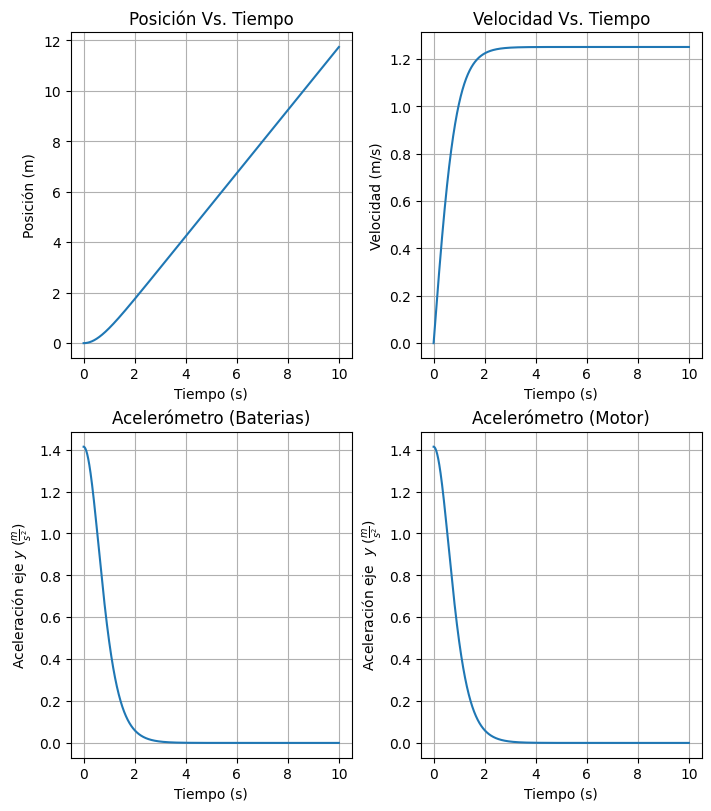

In [ ]:
n_steps = int(duration / model.opt.timestep)
time = np.zeros(n_steps)
positions = np.zeros((n_steps,3))
velocities = np.zeros((n_steps,6))
batteries_accelerometer = np.zeros((n_steps, 3))
motor_accelerometer = np.zeros((n_steps, 3))

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)
data.actuator('propeller_control').ctrl = np.array([36])

with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_steps):
    mujoco.mj_step(model, data)
    time[i] = data.time
    positions[i] = data.body('boat').xipos
    velocities[i] = data.body('boat').cvel
    batteries_accelerometer[i] = data.sensor('batteries_accelerometer').data
    motor_accelerometer[i] = data.sensor('motor_accelerometer').data

fig, ax = plt.subplots(2, 2, layout='constrained', figsize=(7, 8))
ax[0, 0].plot(time, positions[:, 1])
ax[0, 0].set(title='Posición Vs. Tiempo', ylabel='Posición (m)', xlabel='Tiempo (s)')
ax[0, 0].grid()

ax[0, 1].plot(time, velocities[:, 4])
ax[0, 1].set(title='Velocidad Vs. Tiempo', ylabel='Velocidad (m/s)', xlabel='Tiempo (s)')
ax[0, 1].grid()


ax[1, 0].plot(time, batteries_accelerometer[:, 1])
ax[1, 0].set(title='Acelerómetro (Baterias)', ylabel=r'Aceleración eje $y$ $(\frac{m}{s^2})$', xlabel='Tiempo (s)')
ax[1, 0].grid()

ax[1, 1].plot(time, motor_accelerometer[:, 1])
ax[1, 1].set(title='Acelerómetro (Motor)', ylabel=r'Aceleración eje  $y$ $(\frac{m}{s^2})$', xlabel='Tiempo (s)')
ax[1, 1].grid()

plt.show()

In [ ]:
duration = 10   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

options = mujoco.MjvOption()
mujoco.mjv_defaultOption(options)
options.flags[mujoco.mjtVisFlag.mjVIS_TRANSPARENT] = True

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)
data.actuator('propeller_control').ctrl = np.array([36])
data.actuator('angle_control').ctrl = np.array([np.deg2rad(90)])

with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      mujoco.mj_step(model, data)
    renderer.update_scene(data, scene_option=options)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


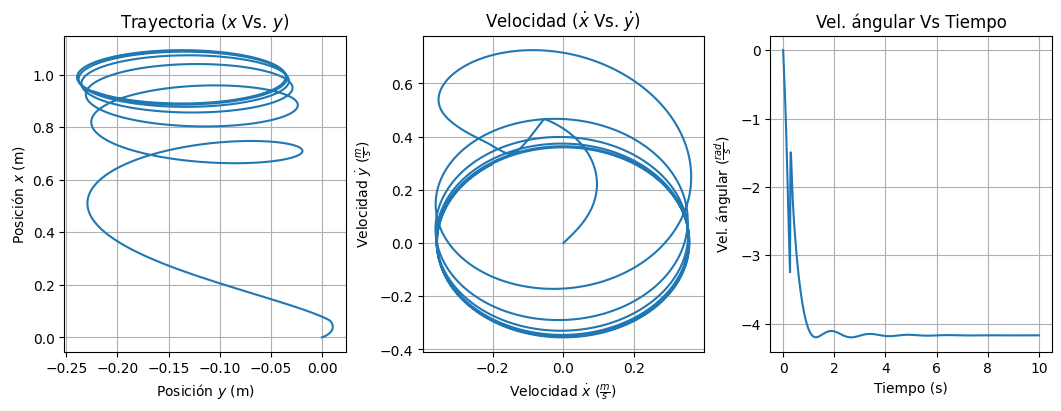

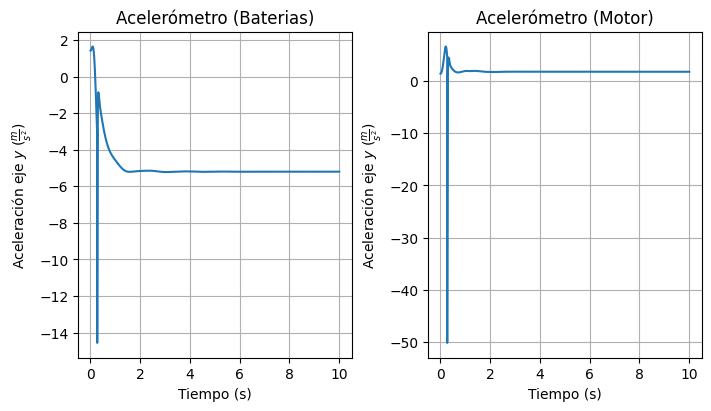

In [ ]:
n_steps = int(duration / model.opt.timestep)
time = np.zeros(n_steps)
positions = np.zeros((n_steps,3))
velocities = np.zeros((n_steps,6))
batteries_accelerometer = np.zeros((n_steps, 3))
motor_accelerometer = np.zeros((n_steps, 3))


mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)
data.actuator('propeller_control').ctrl = np.array([36])
data.actuator('angle_control').ctrl = np.array([np.deg2rad(90)])

with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_steps):
    mujoco.mj_step(model, data)
    time[i] = data.time
    positions[i] = data.body('boat').xipos
    velocities[i] = data.body('boat').cvel
    batteries_accelerometer[i] = data.sensor('batteries_accelerometer').data
    motor_accelerometer[i] = data.sensor('motor_accelerometer').data


fig, ax = plt.subplots(1, 3, layout='constrained', figsize=(10.5, 4))
ax[0].plot(positions[:, 0], positions[:, 1])
ax[0].set(title='Trayectoria ($x$ Vs. $y$)', ylabel='Posición $x$ (m)', xlabel='Posición $y$ (m)')
ax[0].grid()

ax[1].plot(velocities[:, 3], velocities[:, 4])
ax[1].set(title=r'Velocidad ($\dot{x}$ Vs. $\dot{y}$)', xlabel=r'Velocidad $\dot{x}$ ($\frac{m}{s}$)', ylabel=r'Velocidad $\dot{y}$ ($\frac{m}{s}$)')
ax[1].grid()

ax[2].plot(time, velocities[:,2])
ax[2].set(title=r'Vel. ángular Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Vel. ángular ($\frac{rad}{s}$)')
ax[2].grid()
plt.show()

fig, ax = plt.subplots(1, 2, layout='constrained', figsize=(7, 4))
ax[0].plot(time, batteries_accelerometer[:, 1])
ax[0].set(title='Acelerómetro (Baterias)', ylabel=r'Aceleración eje $y$ $(\frac{m}{s^2})$', xlabel='Tiempo (s)')
ax[0].grid()

ax[1].plot(time, motor_accelerometer[:, 1])
ax[1].set(title='Acelerómetro (Motor)', ylabel=r'Aceleración eje $y$ $(\frac{m}{s^2})$', xlabel='Tiempo (s)')
ax[1].grid()

plt.show()